# PUSL3123 – Assessment 1, Exercise 1: Multi-Layer Perceptron (MLP) on CIFAR-10

**Group:** AI-ML Assessment 1 | **Owner of this notebook:** Member 1 (Dulan)

**Objective:** Build and train an MLP with exactly **three trainable layers** on CIFAR-10, then report training, validation and test performance with training/validation loss plots.

**Notebook sections**
1. Title and overview
2. Imports and configuration
3. Reproducibility
4. CIFAR-10 loading
5. Train/validation split
6. Transforms and data loaders
7. Sanity checks
8. MLP architecture
9. Parameter count
10. Training and validation functions
11. Training loop
12. Plots
13. Final test evaluation
14. Results table and observations

**Test-set rule:** the official 10,000-image test set is only used once, in Section 13, after all decisions are fixed. It is never used for tuning or model selection.

## 2. Imports and configuration
All shared settings live in one cell. These values are the group's agreed starting settings (see plan, Section 6); if the group changes any of them, update every notebook.

In [1]:
import sys, time, random, hashlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset

# ---- Shared experiment configuration (agree as a group) ----
SEED        = 42
BATCH_SIZE  = 128
EPOCHS      = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 0.0
VAL_SIZE    = 5000            # taken ONLY from the official 50,000 training images
NUM_WORKERS = 2
DATA_DIR    = "./data"

# Conventional CIFAR-10 per-channel normalisation (same in every notebook)
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2470, 0.2435, 0.2616)

CLASS_NAMES = ["aeroplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"Device: {device}")

Python 3.13.16 | PyTorch 2.14.1+cu130 | torchvision 0.29.1+cu130
Device: cuda


## 3. Reproducibility / random seeds
The seed is set for Python, NumPy and PyTorch (CPU and CUDA) before the split, model creation and training. Full determinism is not guaranteed across hardware/PyTorch versions, but results should be very close.

In [2]:
def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
print(f"Seed set to {SEED}")

Seed set to 42


## 4. CIFAR-10 download and loading
We use `torchvision.datasets.CIFAR10` with the **official** partitions: `train=True` (50,000 images) and `train=False` (10,000 images).

## 5. Train/validation split
The 50,000 official training images are split into **45,000 train / 5,000 validation** using a seeded permutation. The index arrays are generated once and reused for every dataset object, so the split is identical everywhere.

Three dataset objects are built over the same 50,000 images: one for the *train* transform, one for the *evaluation* transform. (In this notebook both use the same non-augmented transform, but the structure matches what Exercise 3 needs, where only the training transform gets augmentation.)

In [3]:
# Deterministic (non-augmented) transform used for train, validation and test in this notebook
base_transform = transforms.Compose([
    transforms.ToTensor(),                              # PIL -> float tensor in [0, 1]
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),        # per-channel normalisation
])
train_transform = base_transform   # Exercise 3 augmentation experiment will replace ONLY this
eval_transform  = base_transform   # validation/test: always deterministic

# Official partitions
full_train_for_train = datasets.CIFAR10(DATA_DIR, train=True,  download=True, transform=train_transform)
full_train_for_val   = datasets.CIFAR10(DATA_DIR, train=True,  download=True, transform=eval_transform)
test_dataset         = datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=eval_transform)

# Seeded 45,000 / 5,000 split of the OFFICIAL TRAINING set only
split_generator = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(full_train_for_train), generator=split_generator).numpy()
val_indices   = np.sort(perm[:VAL_SIZE])
train_indices = np.sort(perm[VAL_SIZE:])

train_dataset      = Subset(full_train_for_train, train_indices.tolist())
validation_dataset = Subset(full_train_for_val,   val_indices.tolist())

# Fingerprint of the split: every notebook must print the same value
split_hash = hashlib.md5(val_indices.tobytes()).hexdigest()
print(f"Split seed: {SEED} | validation-index fingerprint (md5): {split_hash}")

100%|██████████| 170M/170M [02:06<00:00, 1.35MB/s]


Split seed: 42 | validation-index fingerprint (md5): d45cf7fe22a123b42b27274bddc38a8e


## 6. Data loaders
Training data is shuffled (with a seeded generator); validation and test data are not.

In [4]:
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, worker_init_fn=seed_worker,
                          generator=loader_generator, pin_memory=(device.type == "cuda"))
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

## 7. Dataset and batch sanity checks
Training must not start if any of these checks fail.

Train / Val / Test sizes: 45000 / 5000 / 10000
Batch shape: (128, 3, 32, 32) | label dtype: torch.int64
Per-channel batch mean (should be near 0): [-0.039 -0.037 -0.034]
Per-channel batch std  (should be near 1): [1.016 1.017 1.003]
All sanity checks passed.


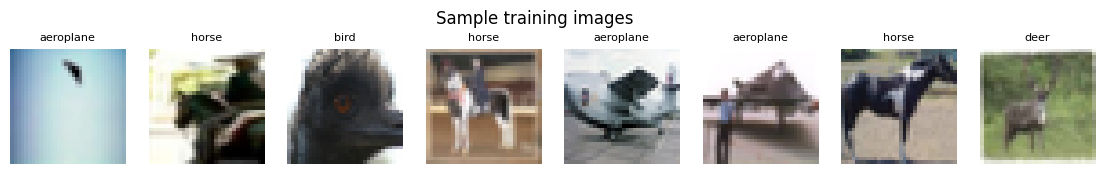

In [5]:
assert len(train_dataset) == 45000,      f"Train size is {len(train_dataset)}"
assert len(validation_dataset) == 5000,  f"Validation size is {len(validation_dataset)}"
assert len(test_dataset) == 10000,       f"Test size is {len(test_dataset)}"
assert len(set(train_indices) & set(val_indices)) == 0, "Train/validation overlap!"
assert len(train_indices) + len(val_indices) == 50000

images, labels = next(iter(train_loader))
assert images.shape == (BATCH_SIZE, 3, 32, 32), f"Unexpected batch shape {images.shape}"
assert labels.min() >= 0 and labels.max() <= 9, "Labels outside 0-9"
assert torch.isfinite(images).all(), "Non-finite pixel values"

print(f"Train / Val / Test sizes: {len(train_dataset)} / {len(validation_dataset)} / {len(test_dataset)}")
print(f"Batch shape: {tuple(images.shape)} | label dtype: {labels.dtype}")
print("Per-channel batch mean (should be near 0):", images.mean(dim=(0, 2, 3)).numpy().round(3))
print("Per-channel batch std  (should be near 1):", images.std(dim=(0, 2, 3)).numpy().round(3))
print("All sanity checks passed.")

# Quick visual check of a few training images (de-normalised for display)
mean_t = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std_t  = torch.tensor(CIFAR_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(14, 2))
for ax, img, lbl in zip(axes, images[:8], labels[:8]):
    ax.imshow((img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[lbl], fontsize=8)
    ax.axis("off")
plt.suptitle("Sample training images")
plt.show()

## 8. MLP architecture

Exactly **three trainable layers** (Flatten and ReLU have no trainable parameters):

| Layer | Operation | Output size |
|---|---|---:|
| Input | Flatten 3×32×32 | 3,072 |
| Trainable layer 1 | Linear 3072 → 512 + ReLU | 512 |
| Trainable layer 2 | Linear 512 → 256 + ReLU | 256 |
| Trainable layer 3 | Linear 256 → 10 | 10 logits |

No softmax at the output: `CrossEntropyLoss` expects raw logits.

In [6]:
class MLP(nn.Module):
    def __init__(self, in_features=3 * 32 * 32, hidden1=512, hidden2=256, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(in_features, hidden1)   # trainable layer 1
        self.fc2 = nn.Linear(hidden1, hidden2)       # trainable layer 2
        self.fc3 = nn.Linear(hidden2, num_classes)   # trainable layer 3 (output logits)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        return self.fc3(x)

set_seed(SEED)                      # seed before model initialisation
model = MLP().to(device)
print(model)

MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3072, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (fc3): Linear(in_features=256, out_features=10, bias=True)
  (relu): ReLU()
)


## 9. Parameter count
Trainable parameters = sum of `p.numel()` over all parameters with `requires_grad=True` (the same method must be used for the CNN in Exercise 2).

In [7]:
def count_trainable_parameters(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

n_params = count_trainable_parameters(model)
trainable_layers = sum(1 for m in model.modules() if isinstance(m, nn.Linear))

# Manual check: (in*out + out) for each Linear layer
manual = (3072*512 + 512) + (512*256 + 256) + (256*10 + 10)
assert n_params == manual
print(f"Trainable layers: {trainable_layers}")
print(f"Trainable parameters: {n_params:,}")

Trainable layers: 3
Trainable parameters: 1,707,274


## 10. Training and validation functions
Loss and accuracy are averaged over **all examples** (weighted by batch size), not as a plain mean of batch means. Evaluation uses `model.eval()` and `torch.no_grad()`.

In [8]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100.0 * correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, 100.0 * correct / total

## 11. Training loop and history
Per-epoch training loss/accuracy and validation loss/accuracy are recorded. **No test data is used here.** The model after the final epoch is the model that gets evaluated on the test set (no checkpoint selection based on test performance).

In [9]:
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

start = time.time()
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    va_loss, va_acc = evaluate(model, validation_loader, criterion, device)

    history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
    history["val_loss"].append(va_loss);   history["val_acc"].append(va_acc)

    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:5.2f}% "
          f"| val loss {va_loss:.4f} acc {va_acc:5.2f}%")
training_time = time.time() - start
print(f"\nTotal training time: {training_time:.1f}s on {device}")

Epoch 01/20 | train loss 1.6563 acc 41.42% | val loss 1.5283 acc 45.64%
Epoch 02/20 | train loss 1.4422 acc 49.18% | val loss 1.4405 acc 48.70%
Epoch 03/20 | train loss 1.3347 acc 52.90% | val loss 1.4389 acc 50.26%
Epoch 04/20 | train loss 1.2445 acc 56.07% | val loss 1.4373 acc 51.34%
Epoch 05/20 | train loss 1.1642 acc 58.66% | val loss 1.4146 acc 51.44%
Epoch 06/20 | train loss 1.0812 acc 61.61% | val loss 1.3869 acc 52.88%
Epoch 07/20 | train loss 1.0111 acc 64.23% | val loss 1.4314 acc 52.84%
Epoch 08/20 | train loss 0.9432 acc 66.53% | val loss 1.4561 acc 53.06%
Epoch 09/20 | train loss 0.8724 acc 68.94% | val loss 1.4983 acc 52.54%
Epoch 10/20 | train loss 0.8035 acc 71.38% | val loss 1.5902 acc 53.12%
Epoch 11/20 | train loss 0.7454 acc 73.45% | val loss 1.5868 acc 53.36%
Epoch 12/20 | train loss 0.6771 acc 75.78% | val loss 1.7011 acc 52.90%
Epoch 13/20 | train loss 0.6274 acc 77.59% | val loss 1.7396 acc 53.08%
Epoch 14/20 | train loss 0.5739 acc 79.55% | val loss 1.8266 acc

## 12. Loss and accuracy plots

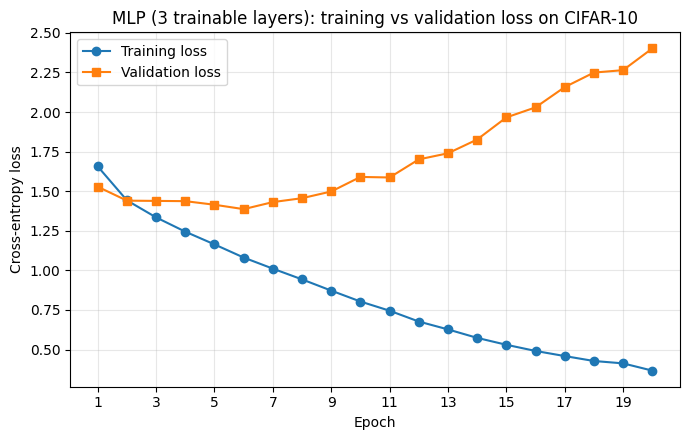

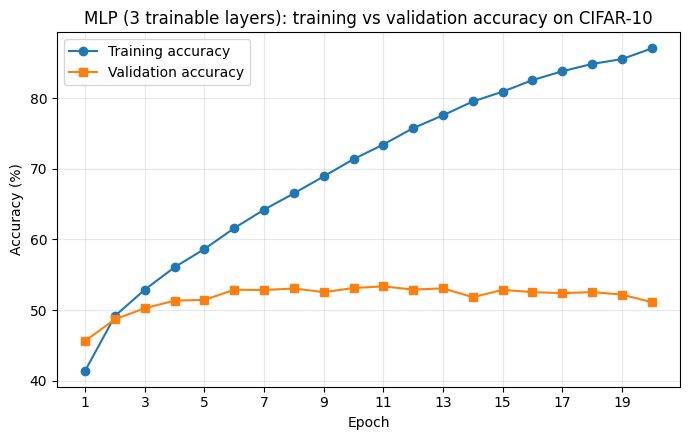

In [10]:
epochs_range = range(1, EPOCHS + 1)

# Required plot: training vs validation loss
plt.figure(figsize=(7, 4.5))
plt.plot(epochs_range, history["train_loss"], marker="o", label="Training loss")
plt.plot(epochs_range, history["val_loss"], marker="s", label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss")
plt.title("MLP (3 trainable layers): training vs validation loss on CIFAR-10")
plt.xticks(list(epochs_range)[::2]); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig("mlp_loss_curve.png", dpi=200); plt.show()

# Supporting plot: accuracy
plt.figure(figsize=(7, 4.5))
plt.plot(epochs_range, history["train_acc"], marker="o", label="Training accuracy")
plt.plot(epochs_range, history["val_acc"], marker="s", label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy (%)")
plt.title("MLP (3 trainable layers): training vs validation accuracy on CIFAR-10")
plt.xticks(list(epochs_range)[::2]); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig("mlp_accuracy_curve.png", dpi=200); plt.show()

## 13. Final test evaluation
The configuration is now fixed. The official test set is evaluated **once** for reporting. Do not change the model based on this result and re-run.

In [11]:
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.2f}%")

Test loss: 2.3773 | Test accuracy: 52.42%


## 14. Results table and observations

In [12]:
results = pd.DataFrame([{
    "Model": "MLP",
    "Trainable layers": trainable_layers,
    "Trainable parameters": n_params,
    "Train accuracy (%)": round(history["train_acc"][-1], 2),
    "Validation accuracy (%)": round(history["val_acc"][-1], 2),
    "Test accuracy (%)": round(test_acc, 2),
    "Final train loss": round(history["train_loss"][-1], 4),
    "Final validation loss": round(history["val_loss"][-1], 4),
    "Test loss": round(test_loss, 4),
    "Training time (s)": round(training_time, 1),
}])
display(results.T.rename(columns={0: "MLP"}))
results.to_csv("mlp_results.csv", index=False)

print("\nConfiguration used:")
print(f"seed={SEED}, batch_size={BATCH_SIZE}, epochs={EPOCHS}, optimiser=Adam, lr={LEARNING_RATE}, "
      f"weight_decay={WEIGHT_DECAY}, split=45000/5000/10000, device={device}")
print(f"Validation-index fingerprint: {split_hash}")

,MLP
Model,MLP
Trainable layers,3
Trainable parameters,1707274
Train accuracy (%),87.06
Validation accuracy (%),51.12
Test accuracy (%),52.42
Final train loss,0.3672
Final validation loss,2.4017
Test loss,2.3773
Training time (s),215.6



Configuration used:
seed=42, batch_size=128, epochs=20, optimiser=Adam, lr=0.001, weight_decay=0.0, split=45000/5000/10000, device=cuda
Validation-index fingerprint: d45cf7fe22a123b42b27274bddc38a8e


### Observations (write these AFTER looking at your own results)

*Fill this in from the actual numbers above. Points to cover for the report:*
- How did training and validation loss change across epochs? Did validation loss start rising while training loss kept falling (overfitting)? At which epoch?
- Gap between final training and validation/test accuracy.
- Why the input is 3,072 values and the output is 10 logits.
- Why flattening loses the 2-D spatial structure of the image (link to the CNN comparison in Exercise 2).
- Limitations: single run, single seed, fixed 20 epochs.